# Gao et al. 2021 — Breast Cancer · 01 Preprocessing
Malignant-cell load → scope to breast → threshold → overdispersed genes → PCA →
Harmony integration (`sample`) → UMAP → **Gate 1** (mixing + continuity).

In [ ]:
import os, sys, glob
os.environ['R_HOME'] = '/home/caleb/miniconda3/envs/scFates/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import anndata as ad
import matplotlib.pyplot as plt
import scipy.sparse as sp
from scipy.sparse.csgraph import connected_components
from sklearn.neighbors import NearestNeighbors
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
# paths: cwd = <root>/mesencontext/claude/<Category>/<Dataset>  (two levels below Puram)
name = os.path.basename(os.getcwd())                    # Gao2021_Breast-2
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Breast
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name.replace('-2',''))
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Gao2021_Breast-2 | category: Breast


## Load — two leaf matrices, breast malignant only
The Gao2021 folder is a mixed **breast + anaplastic-thyroid** atlas across two leaves
(`Breast/`: DCIS1, TNBC1-3; `Breast_and_thyroid/`: ATC1-5 thyroid + TNBC4-5). This is the
designated **Breast Cancer** dataset, so the thyroid ATC samples are out of scope. The two
leaves use different genome-annotation versions, so genes are **inner-joined** (22,164 shared;
an outer join would fabricate ~11k source-confounded zero columns that confound Harmony).

In [ ]:
leaf1 = load_CCCA_adata(os.path.join(pth_in, 'Breast'))
leaf2 = load_CCCA_adata(os.path.join(pth_in, 'Breast_and_thyroid'))
inter = sorted(set(leaf1.var_names) & set(leaf2.var_names))
print('leaf gene overlap (inner join):', len(inter), 'of', leaf1.n_vars, '/', leaf2.n_vars)
BREAST = ['DCIS1','TNBC1','TNBC2','TNBC3','TNBC4','TNBC5']
def scope(a):
    m = (a.obs['celltype']=='Malignant') & (a.obs['sample'].isin(BREAST))
    return a[m, inter].copy()
adata = ad.concat({'Breast':scope(leaf1),'Breast_and_thyroid':scope(leaf2)},
                  join='inner', merge='same', label='source')
adata.obs_names_make_unique()
print('breast malignant:', adata.shape, '| samples:', sorted(adata.obs['sample'].unique()))
print('expression: X max %.2f (log1p of UMI counts, normalized by loader)' % adata.X.max())

Loading ../../../../../../data/unzip/CCCA/Data_Gao2021_Breast/Breast
Done.
Loading ../../../../../../data/unzip/CCCA/Data_Gao2021_Breast/Breast_and_thyroid
Done.
leaf gene overlap (inner join): 22164 of 33694 / 33538
breast malignant: (6606, 22164) | samples: ['DCIS1', 'TNBC1', 'TNBC2', 'TNBC3', 'TNBC4', 'TNBC5']
expression: X max 9.29 (log1p of UMI counts, normalized by loader)


## Threshold under-populated samples
Anchor floor = 100 cells. Smallest breast sample is TNBC3 (195) — the floor keeps all 6 samples
(no sample is a sparse-batch liability), so thresholding is non-binding here.

In [ ]:
n = adata.obs['sample'].value_counts()
print('per-sample malignant counts:', dict(zip(n.index, n.values.astype(int))))
FLOOR = 100
keep = n.index[n >= FLOOR]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'FLOOR={FLOOR} -> kept {len(keep)}/{len(n)} samples; {adata.shape[0]} cells; min per-sample={int(n.min())}')

per-sample malignant counts: {'TNBC5': np.int64(2647), 'TNBC4': np.int64(1249), 'DCIS1': np.int64(1101), 'TNBC1': np.int64(796), 'TNBC2': np.int64(618), 'TNBC3': np.int64(195)}
FLOOR=100 -> kept 6/6 samples; 6606 cells; min per-sample=195


## Gene filter + overdispersed selection + PCA (no scaling)
Following the reference protocol: `find_overdispersed` for feature selection, PCA on the
overdispersed genes. **No `sc.pp.scale`** before PCA (absent from the reference; it has caused
false NO-GOs in prior runs).

In [ ]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
adata.raw = adata
sc.pp.pca(adata, n_comps=50, mask_var='highly_variable')
print('PCA variance ratio[:10]:', np.round(adata.uns['pca']['variance_ratio'][:10], 4).tolist())

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 2696 over-dispersed features (0:00:02) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 2696
PCA variance ratio[:10]: [0.2835, 0.1284, 0.066, 0.0364, 0.0198, 0.0146, 0.0111, 0.0092, 0.0084, 0.0073]


## Harmony integration — theta & n_pcs sweep (Gate 1 evidence)
Breast tumours are strongly patient-specific (CNV-driven), so integration strength must be swept,
not assumed. iLISI (per-neighbourhood inverse-Simpson of `sample`) is read across theta with
n_pcs in the robust 20-40 band. Mixing rises with theta and **plateaus near theta=8**; the kNN
graph is a **single connected component at every theta** — continuous, not a patient archipelago.

In [ ]:
def ilisi(rep, labels, k=90):
    k = min(k, len(rep)-1)
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]
    out = np.empty(len(rep))
    for i in range(len(rep)):
        _,cnt = np.unique(L[i], return_counts=True); p = cnt/L.shape[1]; out[i] = 1.0/np.sum(p**2)
    return out
n_samp = adata.obs['sample'].nunique()
il_pre = np.median(ilisi(adata.obsm['X_pca'][:,:30], adata.obs['sample'].values))
print(f'pre-Harmony iLISI median = {il_pre:.2f} of {n_samp} samples')
sweep = {}
for th in [1,2,3,5,8,10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=20, random_state=SEED)
    rep = adata.obsm['X_pca_harmony'][:,:30]
    A = sc.pp.neighbors(adata, n_pcs=30, use_rep='X_pca_harmony', copy=True).obsp['connectivities']
    ncomp,_ = connected_components(A, directed=False)
    sweep[th] = (float(np.median(ilisi(rep, adata.obs['sample'].values))), int(ncomp))
print('theta -> (iLISI median, kNN components):', {k:(round(v[0],2),v[1]) for k,v in sweep.items()})
THETA, NPCS = 8, 30
print(f'selected theta={THETA}, n_pcs={NPCS} (mixing plateaus ~theta=8; one connected component throughout)')
sce.pp.harmony_integrate(adata, 'sample', theta=THETA, max_iter_harmony=20, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=NPCS, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

pre-Harmony iLISI median = 1.00 of 6 samples
theta -> (iLISI median, kNN components): {1: (1.0, 1), 2: (1.12, 1), 3: (1.36, 1), 5: (1.5, 1), 8: (1.59, 1), 10: (1.53, 1)}
selected theta=8, n_pcs=30 (mixing plateaus ~theta=8; one connected component throughout)


## Detached-island check
Radius graph at 6x median nearest-neighbour distance; keep the largest connected component.

In [ ]:
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
removed = int((lab!=main).sum())
print(f'radius-graph components={ncomp}; removed {removed} cells in {ncomp-1} detached islands')
if removed > 0:
    adata = adata[lab==main].copy()
    sc.pp.neighbors(adata, n_pcs=NPCS, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
    sc.tl.umap(adata, spread=1.3, random_state=SEED)
print('cells after island removal:', adata.shape[0])

radius-graph components=2; removed 1 cells in 1 detached islands
cells after island removal: 6605


## Sub-region biology BEFORE the Gate-1 GO
Leiden lobes, cycling fraction, breast subtype markers and embryonic signatures — settle each
region's identity so the trajectory is scoped honestly (biology before geometry).

In [ ]:
sc.tl.leiden(adata, resolution=0.3, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
prolif = [g for g in ['MKI67','UBE2C','STMN1','TOP2A','CDK1','TYMS','PCNA'] if g in adata.var_names]
sc.tl.score_genes(adata, prolif, score_name='prolif_score', random_state=SEED)
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.dropna().drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,l in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=l, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
    print(f'{l}: {g.size}/{feat[src].size} genes present')
# graph-smoothed signatures for a de-noised geography read
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,l in enumerate(['Gast','pSom','Crest']): adata.obs[l+'_sm'] = S[:,j]
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('cycling fraction per lobe:', adata.obs.groupby('lobe',observed=True)['cycling'].mean().round(3).to_dict())
print('smoothed module means per lobe:')
print(adata.obs.groupby('lobe',observed=True)[['Gast_sm','pSom_sm','Crest_sm']].mean().round(3))
print('overall cycling fraction: %.3f' % adata.obs['cycling'].mean())
print('-> one continuous low/mixed-cycling body; lobes are patient-territorial, share the signature axis. One trajectory object.')

Gast: 79/81 genes present
pSom: 94/98 genes present
Crest: 103/104 genes present
lobe sizes: {'5': 1601, '4': 1307, '1': 1179, '0': 751, '2': 705, '8': 464, '6': 416, '7': 124, '3': 58}
cycling fraction per lobe: {'0': 0.04, '1': 0.522, '2': 0.07, '3': 0.0, '4': 0.021, '5': 0.155, '6': 0.091, '7': 0.621, '8': 0.056}
smoothed module means per lobe:
      Gast_sm  pSom_sm  Crest_sm
lobe                            
0      -0.013    0.026    -0.037
1      -0.033    0.012    -0.039
2      -0.014    0.017    -0.050
3       0.006   -0.001    -0.041
4      -0.014    0.011    -0.046
5      -0.022    0.021    -0.039
6      -0.053    0.039    -0.066
7      -0.048    0.051    -0.044
8      -0.035    0.016    -0.050
overall cycling fraction: 0.168
-> one continuous low/mixed-cycling body; lobes are patient-territorial, share the signature axis. One trajectory object.


## Annotation — data markers + publication meta-programs
Cells are annotated by breast malignant state combining data-derived marker scores
(Basal / Luminal-epithelial / EMT-mesenchymal / Cycling) with the Gao et al. 2021 3CA recurrent
**meta-programs** carried in the metadata (`mp_top`: Stress, EMT, Cell-Cycle, Hypoxia, MYC ...).

In [ ]:
mk = {'Basal':['KRT5','KRT14','KRT17','TP63'],'Luminal':['KRT8','KRT18','KRT19','EPCAM'],
      'EMT':['VIM','FN1','ZEB1','ZEB2'],'Cycling':['MKI67','TOP2A']}
for grp,gs in mk.items():
    gs=[g for g in gs if g in adata.var_names]
    sc.tl.score_genes(adata, gs, score_name='mk_'+grp, random_state=SEED)
score_cols=['mk_'+k for k in mk]
adata.obs['celltype'] = (adata.obs[score_cols].idxmax(1).str.replace('mk_','')).astype('category')
print('marker-state assignment:', adata.obs['celltype'].value_counts().to_dict())
print('publication meta-program (mp_top) top states:',
      adata.obs['mp_top'].astype(str).value_counts().head(6).to_dict())

marker-state assignment: {'Luminal': 4515, 'Cycling': 762, 'Basal': 702, 'EMT': 626}
publication meta-program (mp_top) top states: {'Stress': 757, 'Protein maturation': 707, 'EMT III': 633, 'Cell Cycle - G2/M': 513, 'MP41 (Unassigned)': 441, 'Hypoxia': 438}


## House linear layout (rigid rotation) + Gate 1 verdict
X_umap_lin = rigid SVD rotation of the UMAP (NOT a re-embedding) with the Gast/pSom origin on the
left — used for the (3.5,1.5) linear-trajectory panels downstream, preserving the geometry.

In [ ]:
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
aspect = c.std(0).max()/c.std(0).min()
_,_,vt = np.linalg.svd(c, full_matrices=False)
th_rot = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[np.cos(-th_rot),-np.sin(-th_rot)],[np.sin(-th_rot),np.cos(-th_rot)]])
xyr = c @ Rm.T
origin = (S[:,0]+S[:,1]) - S[:,2]; w = origin - origin.min()
if np.average(xyr[:,0], weights=w) > 0: xyr[:,0] = -xyr[:,0]
adata.obsm['X_umap_lin'] = xyr
print(f'manifold aspect (max/min std) = {aspect:.2f}')
il_post = sweep[THETA][0]
print(f'iLISI median: pre-Harmony {il_pre:.2f} -> theta={THETA} {il_post:.2f} of {n_samp} samples')
print(f'{n_samp} samples share ONE continuous manifold (single connected component; {removed} island cells removed).')
print('GATE 1: samples intermix per-neighbourhood on one continuous manifold -> PASS (GO)')

manifold aspect (max/min std) = 1.06
iLISI median: pre-Harmony 1.00 -> theta=8 1.59 of 6 samples
6 samples share ONE continuous manifold (single connected component; 1 island cells removed).
GATE 1: samples intermix per-neighbourhood on one continuous manifold -> PASS (GO)


## Save processed data + sample figure

In [ ]:
protect = {'sample','source','celltype','cell_type','cell_cycle_phase','lobe','mp_top','mp_assignment'}
for col in list(adata.obs.columns):
    if col in protect:
        adata.obs[col] = adata.obs[col].astype(str).astype('category'); continue
    s = adata.obs[col]
    if s.dtype == object:
        conv = pd.to_numeric(s, errors='coerce')
        adata.obs[col] = conv if (s.notna().sum()>0 and conv.notna().sum()>=0.9*s.notna().sum()) else s.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (6605, 18227)


saved samples.pdf | cells: 6605


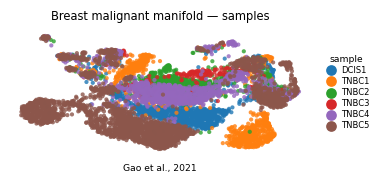

In [ ]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h,l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02,.5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title('Breast malignant manifold — samples', size=7.5)
ax.text(.5,-.12,'Gao et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
plt.show()
print('saved samples.pdf | cells:', plot.shape[0])